# 03 · Fairness check (on IBM LinuxONE)
Gender, race and state are **not** model inputs. Age and chronic conditions are (they matter clinically). We report flag rates per group on the simulated test stream.

In [1]:
import sys, os, platform, subprocess
sys.path.insert(0, os.path.expanduser("~/claimsense/src"))
import xgboost  # before torch (see training.py)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
SHARED = os.path.expanduser("~/shared")
RAW = f"{SHARED}/data/raw"
print(platform.machine(), platform.platform())
print(subprocess.run("grep -E '^Type' /proc/sysinfo; lscpu | grep -io nnpa | head -1", shell=True, capture_output=True, text=True).stdout)

s390x Linux-6.8.0-147-generic-s390x-with-glibc2.39
Type:                 9175
Type 1 Percentage:    0
Type 2 Percentage:    0
Type 3 Percentage:    0
Type 4 Percentage:    0
Type 5 Percentage:    0
nnpa



In [2]:
from claimsense import data as D, fairness as F
claims, _, _ = D.load_all(RAW)
sim = pd.read_csv(f"{SHARED}/data/sim_test_decisions.csv")
g = F.attach_groups(sim, claims)
F.disparity_summary(g).round(4)

,attribute,groups,min_flag_rate,max_flag_rate,max_over_min,worst_group,best_group
0,gender,2,0.0120,0.0125,1.0379,1 (code),2 (code)
1,race,4,0.0104,0.0149,1.4377,code 2,code 5
2,age_band,4,0.0085,0.0153,1.8111,<65,85+
3,State,47,0.0069,0.0321,4.6354,51,24


In [3]:
for a in ["gender", "race", "age_band"]:
    display(F.group_rates(g, a).round(4))

,claims,flag_rate,hold_rate,fpr_honest_providers,flag_ratio_vs_overall
gender,,,,,
2 (code),45451,0.0120,0.0048,0.0127,0.9843
1 (code),33143,0.0125,0.0052,0.0132,1.0216


,claims,flag_rate,hold_rate,fpr_honest_providers,flag_ratio_vs_overall
race,,,,,
code 1,66082,0.0120,0.0048,0.0125,0.9814
code 2,8390,0.0149,0.0064,0.0171,1.2185
code 3,2578,0.0105,0.0066,0.0111,0.8565
code 5,1544,0.0104,0.0032,0.0145,0.8475


,claims,flag_rate,hold_rate,fpr_honest_providers,flag_ratio_vs_overall
age_band,,,,,
65-74,28432,0.0134,0.0052,0.0143,1.0959
75-84,24069,0.0111,0.0044,0.0121,0.9072
<65,13445,0.0153,0.0077,0.0150,1.2531
85+,12648,0.0085,0.0027,0.0093,0.6919


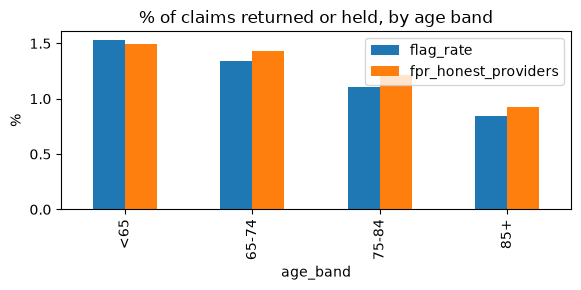

In [4]:
r = F.group_rates(g, "age_band").reindex(["<65", "65-74", "75-84", "85+"])
r[["flag_rate", "fpr_honest_providers"]].mul(100).plot.bar(figsize=(6, 3), title="% of claims returned or held, by age band"); plt.ylabel("%"); plt.tight_layout()

**Finding.** Under-65 beneficiaries (in Medicare mostly people with disabilities or ESRD) are flagged ~1.25x the average because the autoencoder treats them as unusual; race code 2 ~1.2x through correlated features. **Mitigations:** a returned claim is a request to check, never a denial; holds always go to a human; next steps are per-group thresholds or removing age from the claim model, re-measured with this notebook.